# Modelling the US Treasury yield curve
**2023–2024 | Nelson–Siegel fits and principal component analysis of daily rate moves**

How accurately can three coefficients capture each day’s curve? Which rate moves matter most, and what happened during the largest weekly change in the 10-year minus 2-year spread? Run the cells in order from the extracted project folder. Percent is the input unit; one percentage point equals 100 basis points (bp).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_path = Path("data/treasury_yields.csv")
out = Path("results")
out.mkdir(exist_ok=True)
terms = np.array([1, 2, 3, 5, 7, 10, 20, 30])
labels = [f"{n}Y" for n in terms]
rates = pd.read_csv(data_path, parse_dates=["Date"]).set_index("Date").sort_index()
assert list(rates.columns) == labels and rates.index.is_unique
assert rates.notna().all().all() and rates.index.to_series().dt.year.isin([2023, 2024]).all()
print("Trading observations by year:")
print(rates.groupby(rates.index.year).size().to_string())
print("Missing maturity quotes:", int(rates.isna().sum().sum()))
print(rates.head(3).to_string())

Trading observations by year:
Date
2023    250
2024    250
Missing maturity quotes: 0
              1Y    2Y    3Y    5Y    7Y   10Y   20Y   30Y
Date                                                      
2023-01-03  4.72  4.40  4.18  3.94  3.89  3.79  4.06  3.88
2023-01-04  4.71  4.36  4.11  3.85  3.79  3.69  3.97  3.81
2023-01-05  4.78  4.45  4.18  3.90  3.82  3.71  3.96  3.78


## Optional API verification
The included snapshot was assembled from the Treasury’s monthly daily par-yield tables. To verify it against the annual Treasury XML feed, set the switch below to True with internet access. The check compares dates and values without overwriting the input.

In [2]:
VERIFY_ONLINE = False
if VERIFY_ONLINE:
    from urllib.request import urlopen
    import xml.etree.ElementTree as ET

    fresh = []
    for year in (2023, 2024):
        url = ("https://home.treasury.gov/resource-center/data-chart-center/interest-rates/pages/xml"
               f"?data=daily_treasury_yield_curve&field_tdr_date_value={year}")
        with urlopen(url, timeout=45) as response:
            root = ET.parse(response).getroot()
        for record in root.findall(".//{*}properties"):
            date = record.findtext("{*}NEW_DATE")
            fresh.append([pd.Timestamp(date).date(), *[
                float(record.findtext(f"{{*}}BC_{n}YEAR")) for n in terms]])
    api = pd.DataFrame(fresh, columns=["Date", *labels]).set_index("Date").sort_index()
    api.index = pd.to_datetime(api.index)
    pd.testing.assert_frame_equal(rates, api, check_freq=False)
    print("Annual XML matches the included snapshot.")

## Daily Nelson–Siegel fit
For maturity t in years, A = (1 − exp(−λt))/(λt). The fitted yield is β₀ + β₁A + β₂(A − exp(−λt)). β₀ shifts the long-run level; β₁ controls the short end relative to the long end; β₂ bends the middle. For each positive λ on a log grid, fit the coefficients separately on each date by least squares. Choose the shared λ minimising squared error across dates and maturities.

In [3]:
def design(t, decay):
    x = np.asarray(t) * decay
    a = -np.expm1(-x) / x
    return np.column_stack([np.ones_like(a), a, a - np.exp(-x)])

def calibrate(t, values):
    best = None
    for decay in np.geomspace(0.01, 5, 401):
        matrix = design(t, decay)
        beta = np.linalg.lstsq(matrix, values.T, rcond=None)[0].T
        fitted = beta @ matrix.T
        loss = np.square(values - fitted).sum()
        if best is None or loss < best[0]:
            best = (loss, decay, beta, fitted)
    return best[1:]

decay, beta, fitted = calibrate(terms, rates.to_numpy())
factors = pd.DataFrame(beta, index=rates.index, columns=["level", "short_minus_long", "curvature"])
errors = (pd.DataFrame(fitted, index=rates.index, columns=labels) - rates) * 100
def metrics(x):
    return pd.Series({"MAE_bp": np.abs(x).mean(), "RMSE_bp": np.sqrt(np.square(x).mean())})
fit_summary = errors.apply(metrics).T
fit_summary.loc["All"] = metrics(errors.to_numpy().ravel())
factors.to_csv(out / "daily_coefficients.csv")
fit_summary.to_csv(out / "fit_errors.csv")
print(f"Shared decay: {decay:.4f} per year")
print(fit_summary.round(2).to_string())

Shared decay: 0.4939 per year
     MAE_bp  RMSE_bp
1Y     1.71     2.12
2Y     2.70     3.37
3Y     1.46     1.87
5Y     1.22     1.58
7Y     1.50     1.92
10Y    5.50     6.05
20Y   11.00    11.19
30Y    6.95     7.19
All    4.01     5.47


## Withhold the 7-year maturity
Remove the entire 7-year column before choosing λ or fitting coefficients. Compare the reconstructed 7-year yields with a baseline 40% of the way from 5 to 10 years. This tests same-day interpolation.

In [4]:
keep = terms != 7
hold_decay, hold_beta, _ = calibrate(terms[keep], rates.loc[:, keep].to_numpy())
pred7 = (hold_beta @ design([7], hold_decay).T).ravel()
linear7 = rates["5Y"] + 0.4 * (rates["10Y"] - rates["5Y"])
validation = pd.DataFrame({"Observed": rates["7Y"], "Nelson_Siegel": pred7, "Linear": linear7})
hold_errors = validation.iloc[:, 1:].sub(validation["Observed"], axis=0) * 100
hold_summary = hold_errors.apply(metrics).T
validation.to_csv(out / "withheld_7y.csv")
print(f"Withheld calibration decay: {hold_decay:.4f}")
print(hold_summary.round(2).to_string())

Withheld calibration decay: 0.4788
               MAE_bp  RMSE_bp
Nelson_Siegel    2.28     2.91
Linear           1.33     1.71


## PCA of rate moves
Calculate moves across adjacent Treasury observations, centre each maturity in bp and use singular value decomposition to obtain covariance PCA. Keeping all columns in bp preserves relative volatilities. The sign of a component is arbitrary; orient its largest absolute weight positively so scores and weights are reproducible.

In [5]:
moves = rates.diff().dropna() * 100
centered = moves - moves.mean()
_, s, vectors = np.linalg.svd(centered, full_matrices=False)
vectors *= np.sign(vectors[np.arange(len(s)), np.argmax(abs(vectors), axis=1)])[:, None]
share = s**2 / (s**2).sum()
names = ["PC1", "PC2", "PC3"]
weights = pd.DataFrame(vectors[:3].T, index=labels, columns=names)
scores = pd.DataFrame(centered.to_numpy() @ vectors[:3].T, index=moves.index, columns=names)
weights.to_csv(out / "pca_weights.csv")
scores.to_csv(out / "daily_pca_scores.csv")
print("Explained variance (%):", np.round(100 * share[:3], 2))
print(weights.round(3).to_string())

Explained variance (%): [87.05 10.26  1.58]
       PC1    PC2    PC3
1Y   0.281 -0.480  0.759
2Y   0.404 -0.431 -0.090
3Y   0.415 -0.238 -0.350
5Y   0.405 -0.012 -0.312
7Y   0.385  0.160 -0.167
10Y  0.345  0.284  0.005
20Y  0.288  0.430  0.242
30Y  0.266  0.485  0.329


## Trading case study
Compare first-to-last observed spread changes within calendar weeks. Require five observations for a full, comparable Monday–Friday week. A positive change in the 10Y minus 2Y spread is steepening; a negative change is flattening. Endpoint movements exclude the move into Monday.

In [6]:
spread = 100 * (rates["10Y"] - rates["2Y"])
weeks = spread.groupby(spread.index.to_period("W-FRI")).agg(["first", "last", "size"])
eligible = weeks.loc[weeks["size"] == 5].copy()
eligible["change_bp"] = eligible["last"] - eligible["first"]
selected = eligible["change_bp"].abs().idxmax()
week = rates.loc[rates.index.to_period("W-FRI") == selected]
start, end = week.index[[0, -1]]
week_changes = (week.iloc[-1] - week.iloc[0]) * 100
print(f"{start.date()} to {end.date()} | {len(eligible)} eligible weeks")
print(f"10Y minus 2Y: {spread.loc[start]:.0f} to {spread.loc[end]:.0f} bp")
print(week_changes.round(1).to_string())
print("Daily component scores during the endpoint-to-endpoint move:")
print(scores.loc[week.index[1:]].round(2).to_string())
eligible.to_csv(out / "weekly_spreads.csv")

2023-10-16 to 2023-10-20 | 82 eligible weeks
10Y minus 2Y: -38 to -14 bp
1Y     -1.0
2Y     -2.0
3Y      6.0
5Y     14.0
7Y     19.0
10Y    22.0
20Y    21.0
30Y    22.0
Daily component scores during the endpoint-to-endpoint move:
              PC1    PC2   PC3
Date                          
2023-10-17  30.72   1.51 -3.61
2023-10-18  11.57   8.54 -0.99
2023-10-19   7.48  16.18  3.22
2023-10-20 -16.65   1.39  3.76


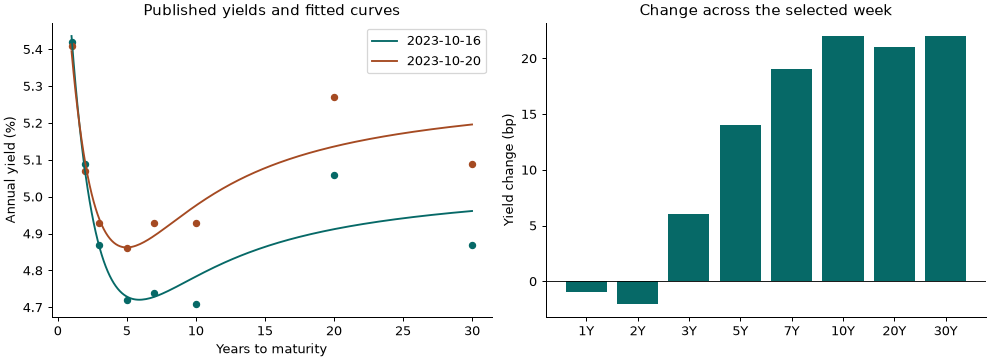

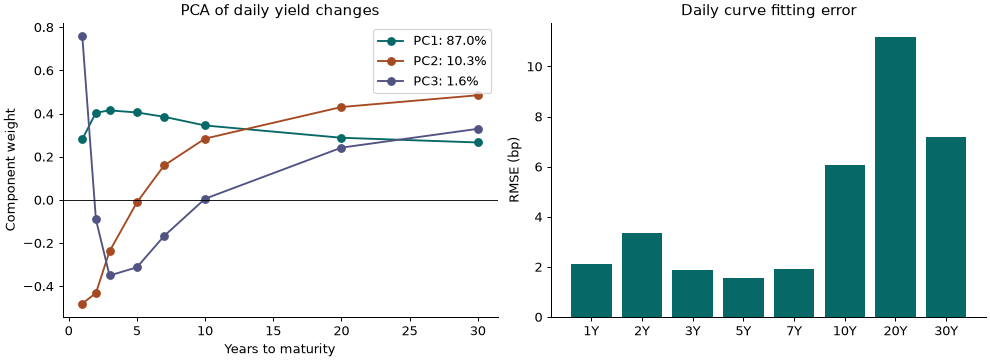

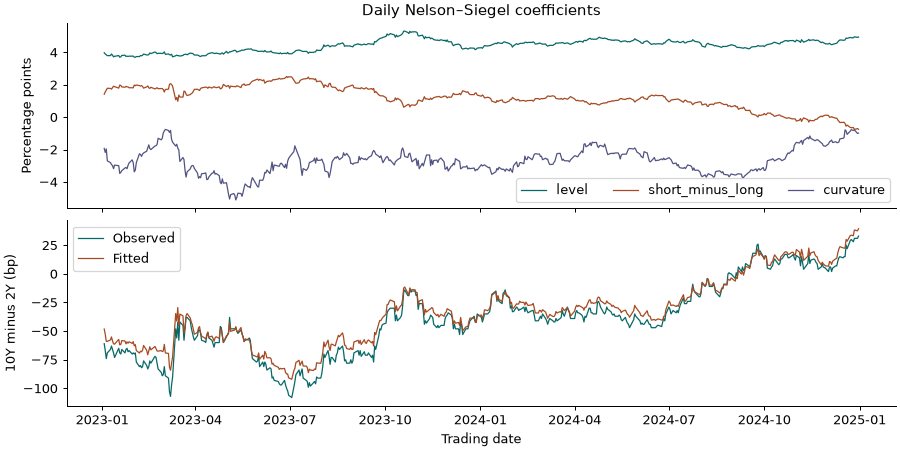

In [7]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
palette = ["#066967", "#a54a22", "#515382"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
grid = np.linspace(1, 30, 200)
for date, color in zip([start, end], palette):
    label = str(date.date())
    axes[0].scatter(terms, rates.loc[date], color=color, s=24)
    axes[0].plot(grid, design(grid, decay) @ factors.loc[date], color=color, label=label)
axes[0].set(xlabel="Years to maturity", ylabel="Annual yield (%)", title="Published yields and fitted curves")
axes[0].legend()
axes[1].bar(labels, week_changes, color=palette[0])
axes[1].axhline(0, color="black", lw=.7)
axes[1].set(ylabel="Yield change (bp)", title="Change across the selected week")
fig.savefig(out / "trading_week.png", dpi=155)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for i, name in enumerate(names):
    axes[0].plot(terms, weights[name], "o-", color=palette[i], label=f"{name}: {100*share[i]:.1f}%")
axes[0].axhline(0, lw=.7, color="black")
axes[0].set(xlabel="Years to maturity", ylabel="Component weight", title="PCA of daily yield changes")
axes[0].legend()
axes[1].bar(labels, fit_summary.loc[labels, "RMSE_bp"], color=palette[0])
axes[1].set(title="Daily curve fitting error", ylabel="RMSE (bp)")
fig.savefig(out / "model_diagnostics.png", dpi=155)
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, constrained_layout=True)
for col, color in zip(factors.columns, palette):
    axes[0].plot(factors.index, factors[col], label=col, color=color, lw=1)
axes[0].legend(ncol=3)
axes[0].set(ylabel="Percentage points", title="Daily Nelson–Siegel coefficients")
fitted_spread = spread + errors["10Y"] - errors["2Y"]
axes[1].plot(spread, label="Observed", lw=1, color=palette[0])
axes[1].plot(fitted_spread, label="Fitted", lw=1, color=palette[1])
axes[1].set(ylabel="10Y minus 2Y (bp)", xlabel="Trading date")
axes[1].legend()
fig.savefig(out / "coefficient_history.png", dpi=155)
plt.show()

## Sources
[US Treasury daily par yields](https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_yield_curve) · [Treasury XML feed](https://home.treasury.gov/treasury-daily-interest-rate-xml-feed) · [Nelson and Siegel (1987), Parsimonious Modeling of Yield Curves](https://doi.org/10.1086/296409)

The accompanying report interprets the numerical results and the selected week. Benchmark par yields describe a curve; calculating trading profit would additionally require security prices and positions.